# Bee1004 — DEMO

A fast, concrete result on **real data** for a live demo. Instead of the whole 38 GB brain,
this analyses one **full-resolution crop** (~1024², all 109 z-planes).

**Why it's fast:** the file is uncompressed, so HIVE reads only the crop's bytes off disk —
about **230 MB instead of 38 GB** (~160× less I/O). The whole notebook runs in a couple of
minutes.

**What you'll show:**
1. A raw → background-corrected → segmented figure with a real object count
2. A rotating 3D reconstruction GIF of PDF+ neurons
3. A table of real measurements (area, intensity, in microns)

Run top to bottom. Only the crop box in cell 3 needs your attention.

In [4]:
import sys, time, warnings
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, tifffile

warnings.filterwarnings("ignore")
for _c in [Path.cwd(), *Path.cwd().parents]:
    if (_c / "hive").is_dir() and (_c / "prep_stack.py").is_file():
        sys.path.insert(0, str(_c)); break
plt.rcParams.update({"figure.dpi": 600, "image.cmap": "magma"})

BEE = Path(
    "/Users/deathyang/Desktop/20x tile z stack of a lobe dark.tif"
)
OUT = Path("bee1004_demo"); OUT.mkdir(exist_ok=True)
PIXEL_XY, PIXEL_Z = 0.161636973345304, 0.6      # um, from the OME metadata

import prep_stack
try:
    info = prep_stack.inspect(BEE)
except PermissionError:
    raise SystemExit(
        "macOS is blocking the Google Drive folder. Grant Terminal/Jupyter Full Disk Access "
        "(System Settings > Privacy & Security), restart it, and re-run. Or copy the file to ~/Desktop."
    )

FileNotFoundError: [Errno 2] No such file or directory: '/Users/deathyang/Desktop/20x tile z stack of a lobe dark.tif'

## 1. Pick a crop with visible neurons

Start with the center of the mosaic. If it's empty, nudge `CY`/`CX` and re-run — each try only
reads ~230 MB, so it's quick. `SIZE = 1024` (≈165 µm) is a good demo size; 1536 still runs fast.

In [ ]:
# ---- the crop (full-resolution pixels) -----------------------------------------
_, H, W = info["shape"]
CY, CX = H // 2, W // 2          # center of the mosaic; move if this region is empty
SIZE   = 1024                    # crop side in px (165 um). 1536 also fine.
# --------------------------------------------------------------------------------

y0, x0 = CY - SIZE // 2, CX - SIZE // 2
CROP = (y0, y0 + SIZE, x0, x0 + SIZE)

t0 = time.perf_counter()
volume = prep_stack.read_crop_volume(BEE, CROP)      # reads ONLY these bytes
print(f"read {volume.shape} crop in {time.perf_counter()-t0:.1f}s "
      f"({volume.nbytes/1e6:.0f} MB, vs {BEE.stat().st_size/1e9:.0f} GB whole file)")

# quick look: is there signal here?
mip = volume.max(axis=0)
plt.figure(figsize=(6, 6)); plt.imshow(np.clip(mip / np.percentile(mip, 99.5), 0, 1))
plt.title(f"max projection of the crop  ({SIZE*PIXEL_XY:.0f} x {SIZE*PIXEL_XY:.0f} um)")
plt.axis("off"); plt.show()
print("If this is mostly black, change CY/CX above and re-run this cell.")

## 2. Segmentation on the brightest plane — the concrete result

Full HIVE 2D pipeline on one plane: background subtraction, Otsu, cleanup, measurement.

plane z000: 47 objects — 63 -> 47 objects (16 removed); 16 debris


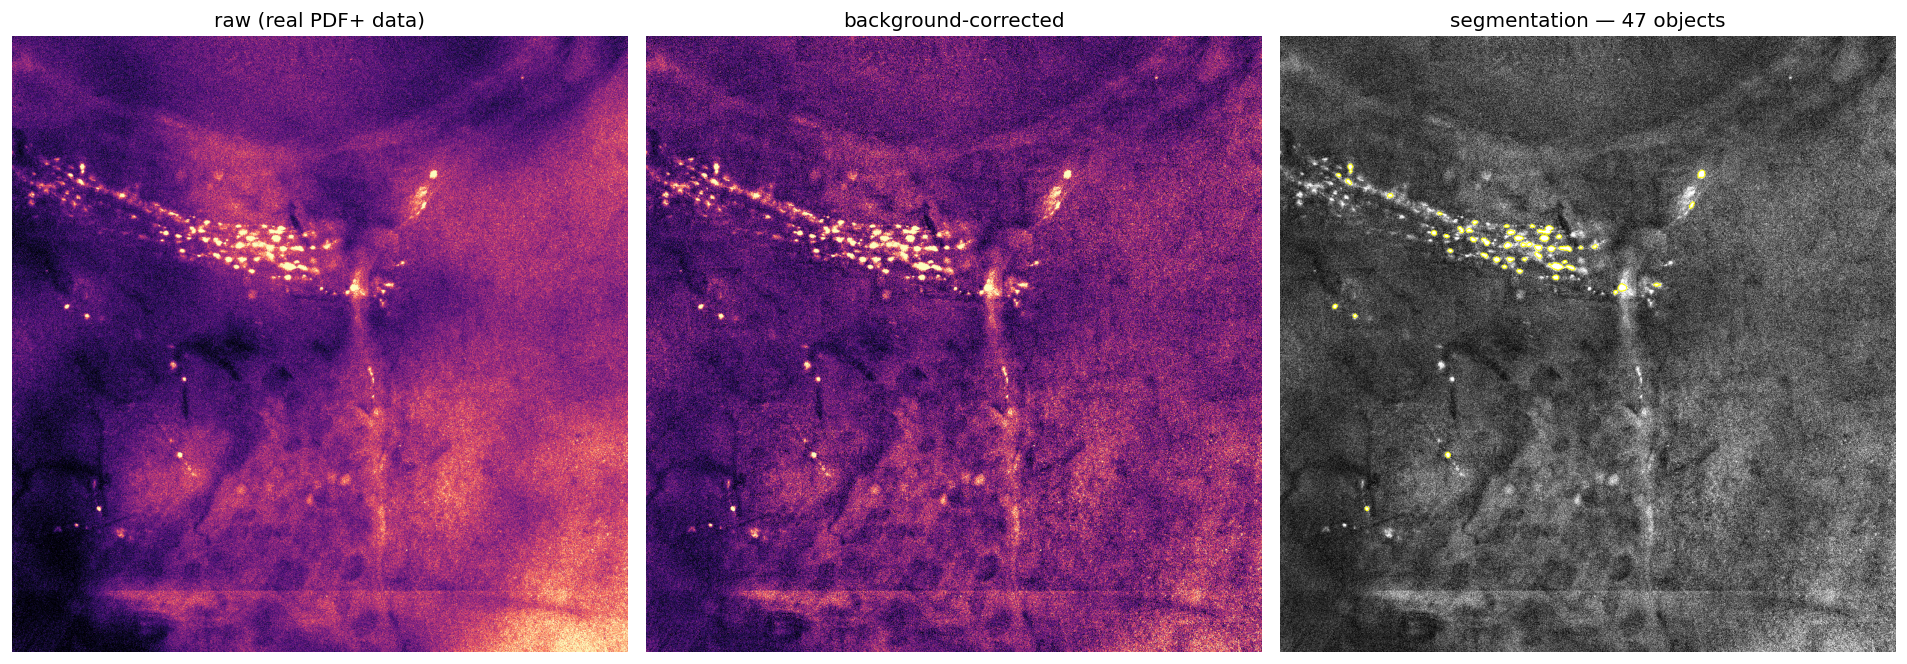

saved bee1004_demo/segmentation_demo.png — drop this straight into your slides


In [ ]:
from hive.config import ArborConfig, HiveConfig, PreprocessConfig, SegmentationConfig
from hive.pipeline import analyze_array
from hive.visualization import create_boundary_overlay
from hive.cleanup import normalize_for_display

# ---- tune if the outlines look wrong -------------------------------------------
TOPHAT_RADIUS, MIN_SIZE = 25, 20    # was 200 -> deleted every bouton; boutons are ~32 px
# --------------------------------------------------------------------------------

cfg2d = HiveConfig(
    output_folder=str(OUT / "2d"), channel="gray",
    voxel_size_xy=PIXEL_XY, voxel_unit="um", save_intermediate=False,
    preprocess=PreprocessConfig(baseline_method="tophat", tophat_radius=TOPHAT_RADIUS,
                                gaussian_sigma=1.0, use_clahe=False),
    segmentation=SegmentationConfig(min_size=MIN_SIZE),
    arbor=ArborConfig(enabled=False),
)

z_best = int(np.argmax([volume[z].mean() for z in range(volume.shape[0])]))
res = analyze_array(volume[z_best], f"z{z_best:03d}", cfg2d)
print(f"plane z{z_best:03d}: {res.object_count} objects — {res.cleanup.summary()}")

fig, ax = plt.subplots(1, 3, figsize=(16, 5.5))
ax[0].imshow(normalize_for_display(volume[z_best])); ax[0].set_title("raw (real PDF+ data)")
ax[1].imshow(normalize_for_display(res.prepared.measurement))
ax[1].set_title("background-corrected")
ax[2].imshow(create_boundary_overlay(res.prepared.measurement, res.labels))
ax[2].set_title(f"segmentation — {res.object_count} objects")
for a in ax: a.axis("off")
plt.tight_layout(); plt.savefig(OUT / "segmentation_demo.png", dpi=600, bbox_inches="tight")
plt.show()
print(f"saved {OUT/'segmentation_demo.png'} — drop this straight into your slides")

## 2b. Boutons + axons — the right tools for thin PDF+ structure

Plain Otsu + `min_size` is built for compact blobs. PDF+ arbors are **bright boutons**
(tiny — a debris filter deletes them) and **thin axons** (dim, few px wide — an intensity
threshold misses them). So:

- **boutons** → threshold the top ~1% brightest pixels, tiny `min_size`
- **axons** → a **Sato ridge filter**, which keys on tube-like *shape*, not brightness
- both on the **max projection**, so an axon travelling through z stays continuous

Bouton density and axon length are exactly the metrics used in PDF circadian-plasticity work,
so this is a real result, not just a picture.

In [ ]:
from hive.baseline import apply_baseline_subtraction
from hive.neurites import detect_neurites
from hive.cleanup import normalize_for_display

# Max projection of the BACKGROUND-CORRECTED volume (axons run through z).
corrected = np.stack([
    apply_baseline_subtraction(volume[z], method="tophat", tophat_radius=TOPHAT_RADIUS,
                               return_baseline=False)[0]
    for z in range(volume.shape[0])
])
projection = corrected.max(axis=0)

neu = detect_neurites(projection, bright_percentile=99.0, bouton_min_size=4,
                      axon_scales=(1, 1.5, 2, 2.5, 3), axon_min_length=50)
print(f"boutons: {neu.n_boutons}   axon skeleton: {neu.axon_length_px} px "
      f"({neu.axon_length_px*PIXEL_XY:.0f} um of PDF+ axon)")

disp = normalize_for_display(projection)
fig, ax = plt.subplots(1, 3, figsize=(18, 6))
ax[0].imshow(disp); ax[0].set_title("PDF+ signal (max projection)")
o1 = np.dstack([disp*0.7]*3); o1[neu.bouton_mask] = [0, 1, 1]
ax[1].imshow(o1); ax[1].set_title(f"boutons: {neu.n_boutons}")
o2 = np.dstack([disp*0.6]*3)
o2[neu.axon_mask] = o2[neu.axon_mask]*0.3 + np.array([0.7, 0, 0]); o2[neu.skeleton] = [1, 0.9, 0]
ax[2].imshow(o2); ax[2].set_title(f"axons: {neu.axon_length_px} px skeleton")
for a in ax: a.axis("off")
plt.tight_layout(); plt.savefig(OUT / "boutons_axons.png", dpi=140, bbox_inches="tight")
plt.show()
print(f"saved {OUT/'boutons_axons.png'} — this is your money slide")

> **Tuning:** boutons too sparse → lower `bright_percentile` (98, 97); axons broken up →
> lower `axon_min_length`, or add larger `axon_scales` for thicker tracts. Report **axon
> length**, not filament *count* — thin ridges fragment on noise, so the count is unstable
> but the total length is robust.

**Check the middle-vs-right panels.** If outlines miss cells, lower `MIN_SIZE`; if they grab
background, raise it; if cells look eaten, raise `TOPHAT_RADIUS`. Re-run — it's instant on a crop.

## 3. The 3D rotating GIF — the visual payoff

A true 3D reconstruction of the cropped volume, rendered as a spinning projection. This is the
"wow" slide.

In [1]:
from hive.pipeline import analyze_zstack

cfg3d = HiveConfig(
    input_path="(in-memory)", output_folder=str(OUT / "3d"), mode="3d", channel="gray",
    voxel_size_xy=PIXEL_XY, voxel_size_z=PIXEL_Z, voxel_unit="um",
    preprocess=PreprocessConfig(baseline_method="tophat",
                                tophat_radius=(2, TOPHAT_RADIUS, TOPHAT_RADIUS),
                                gaussian_sigma=1.0, use_clahe=False),
    segmentation=SegmentationConfig(min_size=MIN_SIZE),
    arbor=ArborConfig(enabled=False),
)

# analyze_zstack wants a path; write the small crop volume once (it is only a few hundred MB).
crop_tif = OUT / "crop_volume.tif"
tifffile.imwrite(crop_tif, volume.astype(np.float32), imagej=True, metadata={"axes": "ZYX"})
cfg3d.input_path = str(crop_tif)

from hive.config import RenderConfig
cfg3d.render = RenderConfig(mode="mip", n_frames=36, fps=15, colormap="magma", downsample=2)

t0 = time.perf_counter()
res3d = analyze_zstack(cfg3d, render_gif=True)
print(f"3D done in {(time.perf_counter()-t0):.0f}s — {res3d.object_count} objects in the volume")

from IPython.display import Image as IPyImage, display as ipy_display
gif = res3d.outputs.get("gif")
if gif and Path(gif).exists():
    print(f"\nGIF: {gif}")
    ipy_display(IPyImage(filename=str(gif)))

NameError: name 'HiveConfig' is not defined

## 4. Real numbers for the slide

In [ ]:
df = res.measurements
print(f"Segmented plane z{z_best:03d}, {SIZE*PIXEL_XY:.0f} x {SIZE*PIXEL_XY:.0f} um of real bee brain:\n")
print(f"  objects           : {len(df)}")
if len(df):
    print(f"  mean area         : {df['area_um2'].mean():.1f} um2")
    print(f"  mean intensity    : {df['intensity_mean'].mean():.0f}")
    print(f"  3D objects (vol)  : {res3d.object_count}")
display(df[["label", "area_um2", "intensity_mean", "integrated_intensity", "eccentricity"]]
        .head(10).round(1))
df.to_csv(OUT / "demo_measurements.csv", index=False)

print(f"""
Deliverables in {OUT.resolve()}:
  segmentation_demo.png   – raw / corrected / segmented figure
  3d/HIVE_3D_rotation.gif  – rotating reconstruction
  demo_measurements.csv    – the numbers above
  3d/HIVE_3D_viewer.html   – interactive 3D (open in a browser, spin it live)
""")

---
### For the talk — what this is

Real confocal data: honeybee brain, PDF+ neurons (a circadian-clock output peptide), 40× A1R,
0.162 µm/pixel. This is a **165 µm full-resolution crop** of a 38 GB whole-brain stack —
analysed in minutes because HIVE reads only the region of interest off disk.

**Say the honest scope:** this is one region, not the whole brain, and the 2D count is
per-plane. It's a real pipeline on real data — a proof of capability, not a finished
whole-brain census. That framing is stronger than overclaiming.

To scale to the whole brain later: `Bee1004_analysis.ipynb` (all 109 planes + full 3D).